In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

num_samples = 500

years_of_experience = np.random.random(size=num_samples) * 20

slope = (200_000 - 60_000) / 18
intercept = 60_000

salaries = slope * years_of_experience + intercept + np.random.normal(0, 15_000, size=num_samples)

data = {'Years_of_Experience': years_of_experience, 'Salary': salaries}
df = pd.DataFrame(data)
df.describe()

,Years_of_Experience,Salary
count,500.000000,500.000000
mean,9.971234,137668.341907
std,5.973768,49826.953891
min,0.101232,34490.166882
25%,4.825594,97379.954398
50%,10.263275,138739.343678
75%,15.122498,179794.465290
max,19.859296,241120.646240


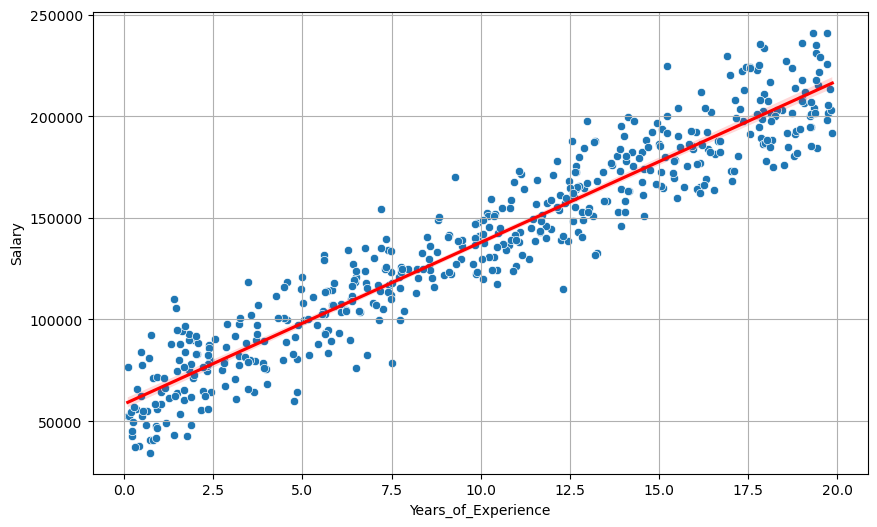

In [5]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Years_of_Experience', y='Salary', data=df)
sns.regplot(x='Years_of_Experience', y='Salary', data=df, scatter=False, color='red')
plt.grid()

In [6]:
def mse_loss(m, b, points):
    """Mean Squared Error Loss Function"""
    total_error = 0
    for i in range(len(points)):
        x = points.iloc[i].Years_of_Experience
        y = points.iloc[i].Salary
        total_error += (y - (m * x + b))**2
    return total_error / float(len(points))

def gradient_descent(m_now, b_now, points, L):
    """Calculates new m and b values through gradient descent"""
    m_grad = 0
    b_grad = 0
    n = len(points)
    for i in range(n):
        x = points.iloc[i].Years_of_Experience
        y = points.iloc[i].Salary
        m_grad += -(2/n) * (y - (m_now * x + b_now)) * x
        b_grad += -(2/n) * (y - (m_now * x + b_now))
    m = m_now - L * m_grad
    b = b_now - L * b_grad
    return m, b

In [7]:
m = 0
b = 0

In [ ]:
L = 0.006
epochs = 10000

for i in range(epochs):
    m, b = gradient_descent(m, b, df, L)
    if i % 500 == 499:
        print(f"Epoch: {i+1:05d} | m: {m:.2f} | b: {b:.2f} | Loss: {mse_loss(m, b, df):.2f}")

Epoch: 00500 | m: 8829.63 | b: 46508.34 | Loss: 263932093.52
Epoch: 01000 | m: 8132.08 | b: 55936.91 | Loss: 228265552.25
Epoch: 01500 | m: 7987.87 | b: 57886.20 | Loss: 226741083.28
Epoch: 02000 | m: 7958.05 | b: 58289.19 | Loss: 226675924.01
Epoch: 02500 | m: 7951.89 | b: 58372.51 | Loss: 226673138.96
Epoch: 03000 | m: 7950.61 | b: 58389.74 | Loss: 226673019.92
Epoch: 03500 | m: 7950.35 | b: 58393.30 | Loss: 226673014.83
Epoch: 04000 | m: 7950.30 | b: 58394.03 | Loss: 226673014.61
Epoch: 04500 | m: 7950.28 | b: 58394.19 | Loss: 226673014.60
Epoch: 05000 | m: 7950.28 | b: 58394.22 | Loss: 226673014.60
Epoch: 05500 | m: 7950.28 | b: 58394.22 | Loss: 226673014.60
Epoch: 06000 | m: 7950.28 | b: 58394.22 | Loss: 226673014.60
Epoch: 06500 | m: 7950.28 | b: 58394.23 | Loss: 226673014.60
Epoch: 07000 | m: 7950.28 | b: 58394.23 | Loss: 226673014.60
Epoch: 07500 | m: 7950.28 | b: 58394.23 | Loss: 226673014.60


In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Years_of_Experience', y='Salary', data=df)
plt.plot(list(range(0, 21)), [m * x + b for x in range(0, 21)], color='red', linewidth=2.5)
plt.grid()

In [ ]:
A = np.ones((len(years_of_experience), 2))
A[:, 0] = years_of_experience
b = salaries.reshape(-1, 1)
np.linalg.inv(np.transpose(A) @ A) @ np.transpose(A) @ b

In [ ]:
def vectorized_mse_loss(theta, x, y):
    """Mean Squared Error Loss Function"""
    n = y.size
    loss = (y - (x @ theta))**2 / n
    return np.sum(loss)

def vectorized_gradient_descent(theta, x, y, L):
    """Calculates new m and b values through gradient descent"""
    n = y.size
    grad = -(2/n) * (x.T @ (y - (x @ theta)))
    return theta - L * grad

In [ ]:
x = df['Years_of_Experience']
x_b = np.c_[np.ones((x.shape[0], 1)), x]
y = df['Salary']
theta = np.zeros(x_b.shape[1])

In [31]:
epochs = 10000
L = 0.006

for i in range(epochs):
    theta = vectorized_gradient_descent(theta, x_b, y, L)
    if i % 500 == 499:
        print(f"Epoch: {i+1:06d} | m: {theta[1]:.4f} | b: {theta[0]:.4f} | Loss: {vectorized_mse_loss(theta, x_b, y):.4f}")

Epoch: 000500 | m: 8829.6320 | b: 46508.3433 | Loss: 263932093.5217
Epoch: 001000 | m: 8132.0800 | b: 55936.9138 | Loss: 228265552.2475
Epoch: 001500 | m: 7987.8667 | b: 57886.1957 | Loss: 226741083.2792
Epoch: 002000 | m: 7958.0517 | b: 58289.1942 | Loss: 226675924.0136
Epoch: 002500 | m: 7951.8877 | b: 58372.5110 | Loss: 226673138.9586
Epoch: 003000 | m: 7950.6134 | b: 58389.7360 | Loss: 226673019.9191
Epoch: 003500 | m: 7950.3499 | b: 58393.2972 | Loss: 226673014.8310
Epoch: 004000 | m: 7950.2954 | b: 58394.0334 | Loss: 226673014.6136
Epoch: 004500 | m: 7950.2842 | b: 58394.1856 | Loss: 226673014.6043
Epoch: 005000 | m: 7950.2819 | b: 58394.2171 | Loss: 226673014.6039
Epoch: 005500 | m: 7950.2814 | b: 58394.2236 | Loss: 226673014.6039
Epoch: 006000 | m: 7950.2813 | b: 58394.2250 | Loss: 226673014.6039
Epoch: 006500 | m: 7950.2813 | b: 58394.2252 | Loss: 226673014.6039
Epoch: 007000 | m: 7950.2812 | b: 58394.2253 | Loss: 226673014.6039
Epoch: 007500 | m: 7950.2812 | b: 58394.2253 | L